# Лабораторная работа 3
### Выполнил: Даулетов Максим Александрович

Добро пожаловать в третью лабораторную работу!
Оформите ваше решение контеста Kaggle в соответствии с этим шаблоном. Ваша задача - показать проверяющим ход ваших рассуждений, поэтому советуем писать много комментариев к коду и приводить комментарии к логике на каждом этапе в текстовых ячейках.
Где необходимо, используйте графики для большей наглядности.

### Настройка Google Colab

Подключение вашего гугл диска (советуем сохранять все важные артефакты именно на диск, чтобы они не удалились при закрытии вкладки с ноутбуком).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [80]:
import random
from PIL import Image

In [3]:
!unzip /content/drive/MyDrive/ML3/ml-mipt-2025-contest-3.zip

Выходные данные были обрезаны до нескольких последних строк (5000).
  inflating: images/images/train/713cf909fa20cc317ea87414518f7b8a.jpg  
  inflating: images/images/train/7144d90cd4670513cf8ace1c37a36caf.jpg  
  inflating: images/images/train/7152642e14c5e2fd294f21b5160a473a.jpg  
  inflating: images/images/train/7155cea2df3e3d21d17c426a1e4096ae.jpg  
  inflating: images/images/train/7155d87e8cf7347b294d4cfea59eb2d7.jpg  
  inflating: images/images/train/715ce64eec96fb71ea3f59897933de94.jpg  
  inflating: images/images/train/715cfb97ab495ca68567cb80fe6add5a.jpg  
  inflating: images/images/train/715d8d97e01e85116df3fc5e40905d63.jpg  
  inflating: images/images/train/7179912080b93d414b0fa8a7a388fbe2.jpg  
  inflating: images/images/train/7180b7a67897394f358257642b0f9e26.jpg  
  inflating: images/images/train/7180d0556e7844adf8d7a83a5927f865.jpg  
  inflating: images/images/train/71810dc6e54af40c0bc01bd4998f90da.jpg  
  inflating: images/images/train/71858a04da75564c18203e90939ad04d.jp

In [5]:
import pandas as pd

df = pd.read_csv('train_labels.csv')

In [7]:
df.head()


,left_eye_x,left_eye_y,right_eye_x,right_eye_y,mouth_x,mouth_y,left_ear_1_x,left_ear_1_y,left_ear_2_x,left_ear_2_y,left_ear_3_x,left_ear_3_y,right_ear_1_x,right_ear_1_y,right_ear_2_x,right_ear_2_y,right_ear_3_x,right_ear_3_y,file_name
0,177.0,124.0,240.0,146.0,208.0,172.0,132.0,97.0,149.0,30.0,190.0,81.0,245.0,102.0,304.0,95.0,268.0,145.0,b4735fa043136534973c17fca358aee9.jpg
1,90.0,231.0,169.0,220.0,134.0,287.0,55.0,202.0,33.0,129.0,77.0,164.0,155.0,153.0,199.0,101.0,207.0,180.0,8d8a9448a43e70077784825b26433d6d.jpg
2,254.0,160.0,340.0,174.0,286.0,245.0,207.0,126.0,207.0,14.0,274.0,94.0,336.0,103.0,422.0,50.0,384.0,155.0,274977dfe9d5cceb1e0a3bb57088164b.jpg
3,559.0,309.0,729.0,353.0,631.0,390.0,470.0,239.0,479.0,87.0,572.0,205.0,756.0,248.0,896.0,188.0,837.0,335.0,dfcd37f5dba0df53a2656b46b8aeb7f4.jpg
4,143.0,159.0,229.0,145.0,186.0,226.0,108.0,121.0,71.0,34.0,141.0,74.0,230.0,59.0,287.0,3.0,290.0,89.0,9ae060a543c60e4dc9d3539cfbc8fb79.jpg


In [6]:
random.seed(141)
np.random.seed(141)

### EDA (исследовательский анализ данных)

В этой лабораторной вы работаете с картинками. Напишите функцию, которая отрисовывала бы ключевые точки на конкретном изображении, это вам пригодится для дебага.
Можете посчитать статистики по картинкам в датасете.

Добавим в датасет размер изображения для удобного изменения и просмотра статистики

In [7]:
IMG_DIR = 'images/images/train'

widths = []
heights = []

for name in df['file_name']:
    img = Image.open(os.path.join(IMG_DIR, name))
    widths.append(img.width)
    heights.append(img.height)
    img.close()

df['width'] = widths
df['height'] = heights

In [9]:
df.head()

,left_eye_x,left_eye_y,right_eye_x,right_eye_y,mouth_x,mouth_y,left_ear_1_x,left_ear_1_y,left_ear_2_x,left_ear_2_y,...,left_ear_3_y,right_ear_1_x,right_ear_1_y,right_ear_2_x,right_ear_2_y,right_ear_3_x,right_ear_3_y,file_name,width,height
0,177.0,124.0,240.0,146.0,208.0,172.0,132.0,97.0,149.0,30.0,...,81.0,245.0,102.0,304.0,95.0,268.0,145.0,b4735fa043136534973c17fca358aee9.jpg,500,334
1,90.0,231.0,169.0,220.0,134.0,287.0,55.0,202.0,33.0,129.0,...,164.0,155.0,153.0,199.0,101.0,207.0,180.0,8d8a9448a43e70077784825b26433d6d.jpg,288,432
2,254.0,160.0,340.0,174.0,286.0,245.0,207.0,126.0,207.0,14.0,...,94.0,336.0,103.0,422.0,50.0,384.0,155.0,274977dfe9d5cceb1e0a3bb57088164b.jpg,500,333
3,559.0,309.0,729.0,353.0,631.0,390.0,470.0,239.0,479.0,87.0,...,205.0,756.0,248.0,896.0,188.0,837.0,335.0,dfcd37f5dba0df53a2656b46b8aeb7f4.jpg,1024,681
4,143.0,159.0,229.0,145.0,186.0,226.0,108.0,121.0,71.0,34.0,...,74.0,230.0,59.0,287.0,3.0,290.0,89.0,9ae060a543c60e4dc9d3539cfbc8fb79.jpg,500,375


In [10]:
df.describe()

,left_eye_x,left_eye_y,right_eye_x,right_eye_y,mouth_x,mouth_y,left_ear_1_x,left_ear_1_y,left_ear_2_x,left_ear_2_y,left_ear_3_x,left_ear_3_y,right_ear_1_x,right_ear_1_y,right_ear_2_x,right_ear_2_y,right_ear_3_x,right_ear_3_y,width,height
count,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000,8997.000000
mean,264.137713,213.916305,342.243192,213.805713,303.464377,274.317328,213.552184,177.718017,203.814827,91.023008,264.054796,139.452595,340.664777,140.364899,401.212960,90.865177,390.837724,179.423808,604.788818,520.366678
std,136.694738,104.321009,157.650823,103.918437,146.595114,131.413452,133.028199,96.815795,143.721056,94.111343,141.639176,86.319160,161.166767,85.807256,190.433651,92.537663,177.541991,96.234946,236.933233,209.065574
min,29.000000,19.000000,55.000000,22.000000,32.000000,55.000000,-44.000000,-37.000000,-188.000000,-214.000000,24.000000,-96.000000,37.000000,-106.000000,0.000000,-235.000000,59.000000,-61.000000,135.000000,101.000000
25%,172.000000,142.000000,236.000000,142.000000,205.000000,183.000000,122.000000,112.000000,106.000000,32.000000,167.000000,82.000000,232.000000,83.000000,275.000000,33.000000,271.000000,115.000000,500.000000,375.000000
50%,226.000000,183.000000,295.000000,183.000000,261.000000,236.000000,181.000000,151.000000,172.000000,69.000000,227.000000,117.000000,295.000000,119.000000,351.000000,71.000000,340.000000,153.000000,500.000000,447.000000
75%,320.000000,260.000000,402.000000,260.000000,360.000000,331.000000,268.000000,219.000000,264.000000,125.000000,321.000000,174.000000,402.000000,175.000000,469.000000,125.000000,450.000000,219.000000,768.000000,683.000000
max,902.000000,786.000000,952.000000,783.000000,976.000000,876.000000,897.000000,844.000000,1063.000000,894.000000,922.000000,827.000000,968.000000,828.000000,1156.000000,935.000000,1011.000000,778.000000,1024.000000,1024.000000


In [8]:
df[["height","width"]].describe()

,height,width
count,8997.000000,8997.000000
mean,520.366678,604.788818
std,209.065574,236.933233
min,101.000000,135.000000
25%,375.000000,500.000000
50%,447.000000,500.000000
75%,683.000000,768.000000
max,1024.000000,1024.000000


Видно что изображения разных размеров, но в среднем около 256 на 256

Наложим ключевые точки на соответствующий рисунок

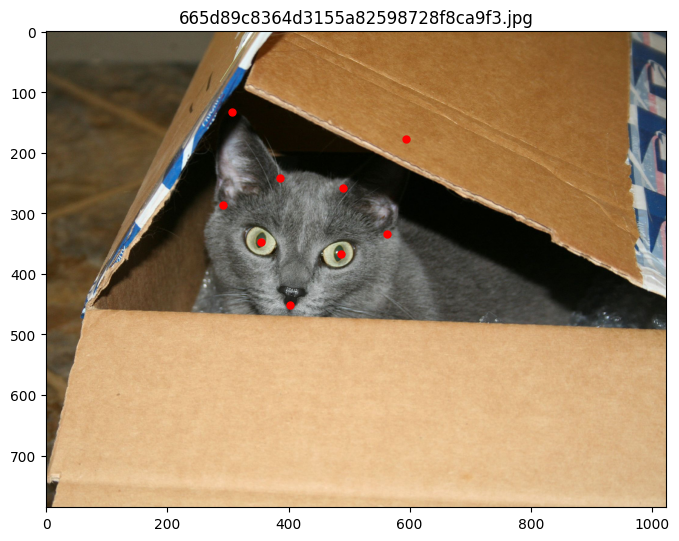

In [9]:
keypoint_bases = [
    'left_ear_1', 'left_ear_2', 'left_ear_3',
    'right_ear_1', 'right_ear_2', 'right_ear_3',
    'left_eye', 'right_eye',
    'mouth'
]
import matplotlib.pyplot as plt
import cv2
import os

def show_cat(id):
    IMG_DIR = 'images/images/train'

    row = df.iloc[id]
    img_path = os.path.join(IMG_DIR, row['file_name'])

    img = cv2.imread(img_path)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.title(row['file_name'])

    for base in keypoint_bases:
        x_col = f"{base}_x"
        y_col = f"{base}_y"

        x = row.get(x_col, None)
        y = row.get(y_col, None)

        if pd.notna(x) and pd.notna(y):
            plt.plot(x, y, 'ro', markersize=5)
    plt.show()


show_cat(5)


Проверим датасет на пропущенные значения

In [10]:
df.isna().sum()

,0
left_eye_x,0
left_eye_y,0
right_eye_x,0
right_eye_y,0
mouth_x,0
mouth_y,0
left_ear_1_x,0
left_ear_1_y,0
left_ear_2_x,0
left_ear_2_y,0


### Preprocessing (подготовка данных)

Мы ожидаем, что в этом разделе вы реализуете кастомный класс для подгрузки данных (cоветуем унаследоваться от `torch.utils.data.Dataset`).

Сначала создадим функцию для приведения всех фото к одному размеру 256 на 256

In [81]:
import cv2
import numpy as np
import os

def preprocess_sample(row, img_dir='images/images/train', target_size=256):
    img_path = os.path.join(img_dir, row['file_name'])
    img = cv2.imread(img_path)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h_orig, w_orig = img.shape[:2]
    scale = min(target_size / w_orig, target_size / h_orig)
    new_w = int(w_orig * scale)
    new_h = int(h_orig * scale)

    resized = cv2.resize(img, (new_w, new_h))

    pad_w = target_size - new_w
    pad_h = target_size - new_h
    pad_left = pad_w // 2
    pad_top = pad_h // 2

    padded = np.full((target_size, target_size, 3), 128, dtype=np.uint8)
    padded[pad_top:pad_top+new_h, pad_left:pad_left+new_w] = resized
    keypoints = []

    for name in keypoint_bases:
        x = row.get(f'{name}_x', np.nan)
        y = row.get(f'{name}_y', np.nan)

        x_new = x * scale + pad_left
        y_new = y * scale + pad_top
        keypoints.append([x_new, y_new])

    keypoints = np.array(keypoints, dtype=np.float32)
    return padded, keypoints

Проверим работоспособность на одном из котиков

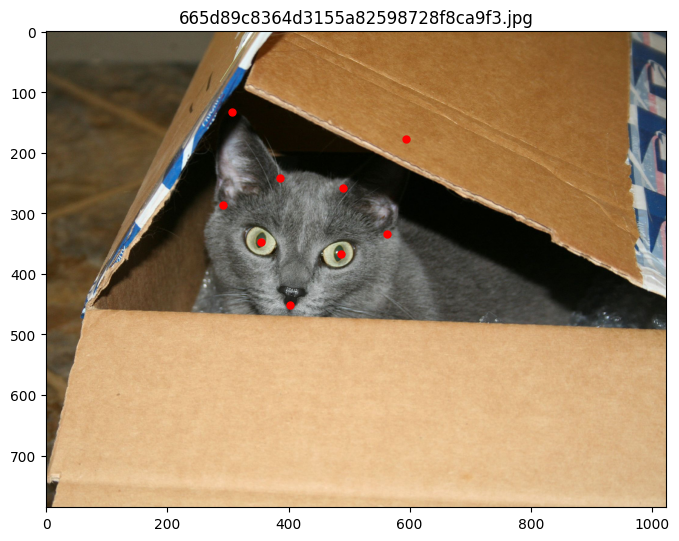

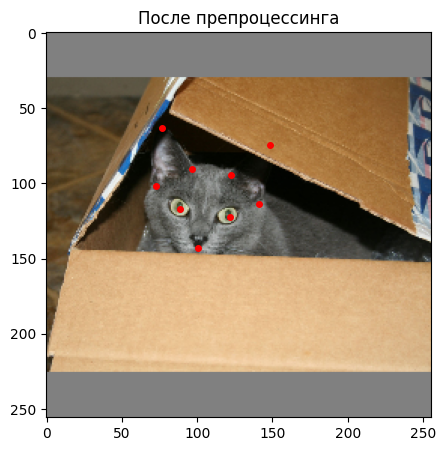

In [82]:
row = df.iloc[5]
show_cat(5)

img_proc, kps = preprocess_sample(row, img_dir='images/images/train', target_size=256)

plt.figure(figsize=(5, 5))
plt.imshow(img_proc)
for i, (x, y) in enumerate(kps):
    plt.plot(x, y, 'ro', markersize=4)
plt.title('После препроцессинга')
plt.show()

Ключевые точки остались на нужных местах

In [13]:
import torch
from torch.utils.data import Dataset
import pandas as pd
import os

class CatKeypointsDataset(Dataset):
    def __init__(self, csv_file, img_dir='images/images/train', target_size=256, transform=None):
        self.annotations = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.target_size = target_size
        self.transform = transform

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, idx):
        row = self.annotations.iloc[idx]
        image, keypoints = preprocess_sample(row, img_dir=self.img_dir, target_size=self.target_size)

        image = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0
        keypoints = torch.from_numpy(keypoints).flatten()

        if self.transform:
            image = self.transform(image)

        return image, keypoints

### Training/evaluation loop

В этом разделе напишите функцию, принимающую модель, оптимизатор, кол-во эпох, и т.д, которая осуществляет обучение с заданными параметрами. Подумайте, что функция будет возвращать.

Смысл этого раздела в том, чтобы не дублировать код обучения для каждого эксперимента. А еще на такую функцию легко накинуть перебор гиперпараметров...

Напишем функцию расчета метрики CMAE и основную функцию обучения.

In [14]:
import torch
import torch.nn as nn
from tqdm import tqdm

def columnwise_mae(preds, targets, num_coords=18):
    mae_per_coord = torch.mean(torch.abs(preds - targets), dim=0)  # [C]
    return torch.mean(mae_per_coord).item()

def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    num_epochs,
    device,
    scheduler=None
):
    model.to(device)
    history = {
        'train_loss': [],
        'val_loss': [],
        'train_cmae': [],
        'val_cmae': []
    }

    for epoch in range(num_epochs):
        model.train()
        train_loss, train_cmae, n_samples = 0.0, 0.0, 0

        for images, targets in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
            images, targets = images.to(device), targets.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)
            train_cmae += columnwise_mae(outputs.detach(), targets) * images.size(0)
            n_samples += images.size(0)

        avg_train_loss = train_loss / n_samples
        avg_train_cmae = train_cmae / n_samples

        model.eval()
        val_loss, val_cmae, n_val_samples = 0.0, 0.0, 0
        with torch.no_grad():
            for images, targets in tqdm(val_loader, desc="Validation"):
                images, targets = images.to(device), targets.to(device)
                outputs = model(images)
                loss = criterion(outputs, targets)

                val_loss += loss.item() * images.size(0)
                val_cmae += columnwise_mae(outputs, targets) * images.size(0)
                n_val_samples += images.size(0)

        avg_val_loss = val_loss / n_val_samples
        avg_val_cmae = val_cmae / n_val_samples

        if scheduler:
            scheduler.step(avg_val_loss)

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['train_cmae'].append(avg_train_cmae)
        history['val_cmae'].append(avg_val_cmae)

        print(f"Epoch {epoch+1} "
              f"train CMAE: {avg_train_cmae:.4f} "
              f"Val CMAE: {avg_val_cmae:.4f}")

    return history

### Prediction function

Реализуйте функцию, которая бы делала предсказания. Функция принимает датасет/даталоадер и модель (мб еще что-то). Эта функция нужна вам, чтобы было удобнее считать метрику (по сути она будет склеивать предсказания из батчей в один массив).

In [15]:
def predict(model, dataloader, device):
    model.eval()
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for images, targets in dataloader:
            images = images.to(device)
            outputs = model(images)

            all_preds.append(outputs.cpu().numpy())
            all_targets.append(targets.numpy())

    predictions = np.concatenate(all_preds, axis=0)
    targets = np.concatenate(all_targets, axis=0)

    return predictions, targets

### Experiments

В этом разделе задаете архитектуры моделей и ставите эксперименты по обучению. Мы ожидаем, что вы зададите модель в виде класса (унаследуетесь от класса `torch.nn.Module`).

Если вы ставили много экспериментов, приведите их в хронологическом порядке, чтобы мы увидели эволюцию ваших рассуждений.

Мы ожидаем увидеть графики train/val лоссов и метрик для ваших экспериментов. Мы ожидаем увидеть визуализацию примеров предсказаний.

In [17]:
from torch.utils.data import DataLoader, random_split
import torchvision.transforms as T

full_dataset = CatKeypointsDataset(csv_file='train_labels.csv', img_dir='images/images/train', target_size=256)
train_size = int(0.9 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

#### Эксперимент 1

Проверим простую сверточную нейронную сеть

In [26]:
class SimpleCNN(nn.Module):
    def __init__(self, num_keypoints=18):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_keypoints)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [30]:
model1 = SimpleCNN()
criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model1.parameters(), lr=0.001)
history1 = train_model(model1, train_loader, val_loader, criterion, optimizer,
                       num_epochs=20, device=device)

Epoch 1/20:   0%|          | 0/225 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Validation: 100%|██████████| 57/57 [00:10<00:00,  5.62it/s]


Epoch 1 train CMAE: 32.6100 Val CMAE: 27.2474


Validation: 100%|██████████| 57/57 [00:10<00:00,  5.58it/s]


Epoch 2 train CMAE: 27.1681 Val CMAE: 25.1977


Validation: 100%|██████████| 57/57 [00:08<00:00,  6.56it/s]


Epoch 3 train CMAE: 26.9731 Val CMAE: 25.5062


... (30 outputs left out)

Validation: 100%|██████████| 57/57 [00:09<00:00,  5.97it/s]


Epoch 19 train CMAE: 22.3393 Val CMAE: 20.5827


Validation: 100%|██████████| 57/57 [00:09<00:00,  6.02it/s]

Epoch 20 train CMAE: 22.1114 Val CMAE: 20.6445


#### Эксперимент 2

Проверим свою глубокую сверточную нейронную сеть

In [18]:
import torchvision.models as models

class ResNetKeypoints(nn.Module):
    def __init__(self, num_keypoints=18):
        super().__init__()
        resnet = models.resnet18(weights=None)
        self.backbone = nn.Sequential(*list(resnet.children())[:-2])
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, num_keypoints)
        )

    def forward(self, x):
        x = self.backbone(x)
        x = self.pool(x)
        x = self.head(x)
        return x

In [19]:
model3 = ResNetKeypoints()
criterion = nn.L1Loss()
for param in model3.backbone.parameters():
    param.requires_grad = False

optimizer3 = torch.optim.Adam(filter(lambda p: p.requires_grad, model3.parameters()), lr=0.001)
history3_warmup = train_model(model3, train_loader, val_loader, criterion, optimizer3,
                              num_epochs=10, device=device)

for param in model3.backbone.parameters():
    param.requires_grad = True

optimizer3_full = torch.optim.Adam(model3.parameters(), lr=0.0001)
scheduler3 = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer3_full, patience=3)
history3_full = train_model(model3, train_loader, val_loader, criterion, optimizer3_full,
                            num_epochs=20, device=device, scheduler=scheduler3)

history3 = {
    k: history3_warmup[k] + history3_full[k] for k in history3_warmup
}

Validation: 100%|██████████| 29/29 [00:06<00:00,  4.61it/s]


Epoch 1 train CMAE: 36.7476 Val CMAE: 24.8838


Validation: 100%|██████████| 29/29 [00:04<00:00,  6.44it/s]


Epoch 2 train CMAE: 25.9367 Val CMAE: 25.6008


Validation: 100%|██████████| 29/29 [00:05<00:00,  5.06it/s]


Epoch 3 train CMAE: 25.8935 Val CMAE: 24.7804


... (50 outputs left out)

Validation: 100%|██████████| 29/29 [00:04<00:00,  6.17it/s]


Epoch 19 train CMAE: 9.5482 Val CMAE: 9.9114


Validation: 100%|██████████| 29/29 [00:06<00:00,  4.82it/s]

Epoch 20 train CMAE: 9.2254 Val CMAE: 8.3913


### Evaluation  (оценка качества модели)

В этом разделе проводите оценку качества вашей итоговой модели (с помощью prediction function из раздела выше).

In [54]:
import matplotlib.pyplot as plt

def plot_training_history(history, title="Training and Validation Metrics"):
    epochs = range(1, len(history['train_loss']) + 1)

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], label='Train Loss', color='tab:blue')
    plt.plot(epochs, history['val_loss'], label='Val Loss', color='tab:orange')
    plt.xlabel('Epoch')
    plt.ylabel('Loss L1')
    plt.title('Training and Validation Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['train_cmae'], label='Train CMAE', color='tab:green')
    plt.plot(epochs, history['val_cmae'], label='Val CMAE', color='tab:red')
    plt.xlabel('Epoch')
    plt.ylabel('CMAE')
    plt.legend()

    plt.suptitle(title, fontsize=16)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

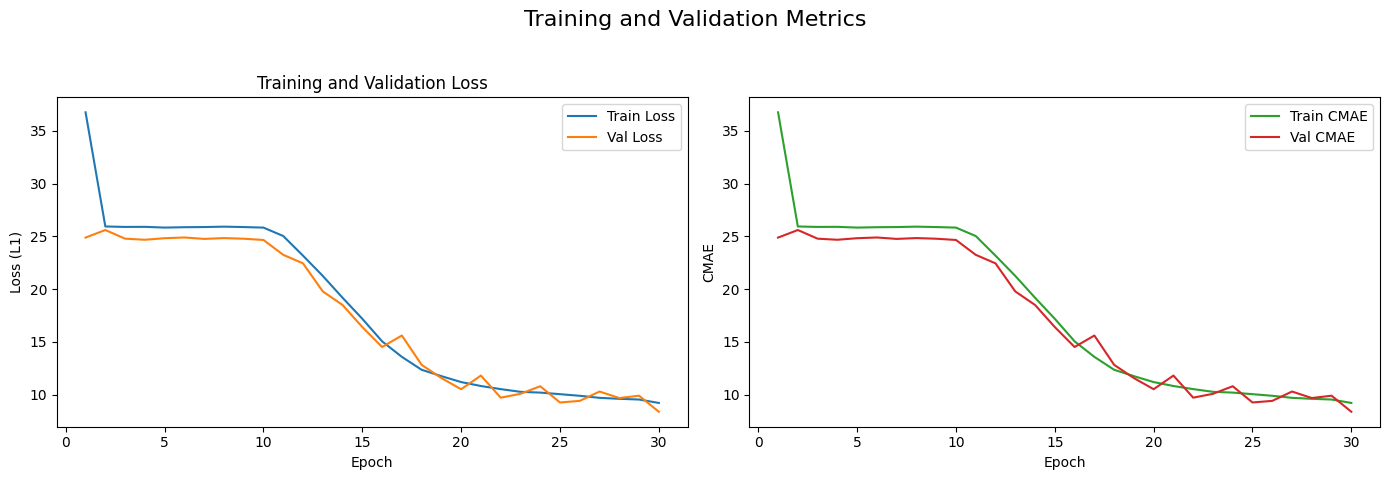

In [56]:
plot_training_history(history3)

In [77]:
def show_prediction(idx):
    model3.eval()

    img_tensor, true_kp_flat = val_dataset[idx]
    img_np = (img_tensor.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    if torch.is_tensor(true_kp_flat):
        true_kp = true_kp_flat.numpy().reshape(-1, 2)
    else:
        true_kp = np.array(true_kp_flat).reshape(-1, 2)
    with torch.no_grad():
        pred_kp_flat = model3(img_tensor.unsqueeze(0).to(device))
        pred_kp = pred_kp_flat.cpu().numpy().reshape(-1, 2)
    cmae_val = np.mean(np.abs(true_kp - pred_kp))
    plt.figure(figsize=(6, 6))
    plt.imshow(img_np)
    plt.scatter(pred_kp[:, 0], pred_kp[:, 1], s=40,c = "lime")

    plt.title(f"CMAE: {cmae_val:.2f} px", fontsize=12)
    plt.tight_layout()
    plt.show()

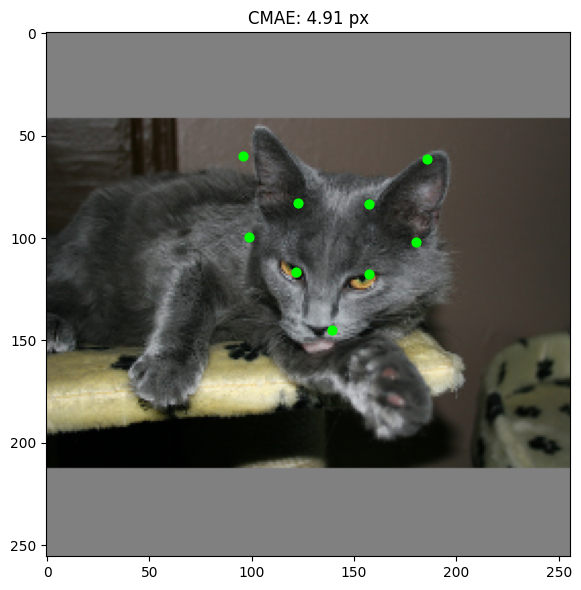

In [78]:
show_prediction(15)

### Conclusion (Выводы)

В этом разделе описываете полученные результаты и проводите анализ выполненной работы.
Что получилось / не получилось и почему?

Было выполнено приведение изображений к одинаковому размеру. Получилось обучить модель и предсказать ключевые точки с неплохой точностью. Лучше всего отработала глубокая сверточная сеть. Результаты можно было бы улучшить с помощью аугментации изображений, также можно было выполнить подбор гиперпараметров для модели.